# Load packages and data

In [1]:
import pandas as pd
import numpy as np

from matplotlib import pyplot as plt
from matplotlib.pyplot import figure

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

In [3]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 500)
pd.set_option('display.max_colwidth', 0) # adjust column width as needed

## data

### claims data

In [7]:
bcbs2018_LA = pd.read_csv('../../../xc2440/SDoH_insurance/data/bcbs2018_LA.csv', low_memory=False)
bcbs2019_LA = pd.read_csv('../../../xc2440/SDoH_insurance/data/bcbs2019_LA.csv', low_memory=False)

In [19]:
filepath = "../../../xc2440/SDoH_insurance/data/bcbs2018_LA.csv"

df_sample = pd.read_csv(filepath, nrows=5)

print(df_sample.columns.tolist())

['Unnamed: 0', 'Member_Wid', 'Group_Wid', 'Hierarchy_Attr_Provider_Wid', 'Member_Medical_Count', 'Member_Drug_Count', 'Member_DOB_Age_Qty', 'Member_Has_Asthma_Episode_Ind', 'Member_Has_Burns_Episode_Ind', 'Member_Has_Cancer_Episode_Ind', 'Member_Has_CHF_Episode_Ind', 'Member_Has_CKD_Episode_Ind', 'Member_Has_Congenital_Anomalies_Episode_Ind', 'Member_Has_COPD_Episode_Ind', 'Member_Has_Crohns_Disease_Episode_Ind', 'Member_Has_Cystic_Fibrosis_Episode_Ind', 'Member_Has_Diabetes_Episode_Ind', 'Member_Has_Glaucoma_Episode_Ind', 'Member_Has_Heart_Pulmonary_Condition_Episode_Ind', 'Member_Has_Hepatitis_C_Episode_Ind', 'Member_Has_Hepatitis_Non_C_Episode_Ind', 'Member_Has_HIV_Episode_Ind', 'Member_Has_Hypertension_Episode_Ind', 'Member_Has_Immunity_Blood_Disorders_Episode_Ind', 'Member_Has_Low_Back_Pain_Episode_Ind', 'Member_Has_Mental_Health_Episode_Ind', 'Member_Has_Metabolic_Disorders_Episode_Ind', 'Member_Has_Multiple_Sclerosis_Episode_Ind', 'Member_Has_Neonatal_Condition_Episode_Ind', 'Me

In [ ]:
# bcbs2018_LA.head(10).to_csv("../data_processed/bcbs2018_LA_head10.csv", index=False)
# bcbs2019_LA.head(10).to_csv("../data_processed/bcbs2019_LA_head10.csv", index=False)

In [8]:
analysis2018 = bcbs2018_LA.copy()
analysis2019 = bcbs2019_LA.copy()

#### comorbidities

In [11]:
com_list = ['Member_Has_ALS_Diag_Ind','Member_Has_AMI_Diag_Ind',
              'Member_Has_Anxiety_Disorders_Diag_Ind','Member_Has_Asthma_Diag_Ind','Member_Has_Burns_Diag_Ind',
 'Member_Has_Cancer_Diag_Ind','Member_Has_Cardiac_Congenital_Anomalies_Diag_Ind','Member_Has_CHF_Diag_Ind',
 'Member_Has_CAD_Diag_Ind','Member_Has_Cerobrovascular_Disease_Diag_Ind','Member_Has_CIDP_Diag_Ind',
 'Member_Has_CKD_Diag_Ind','Member_Has_Congenital_Hydrocephalus_Diag_Ind',
              'Member_Has_Connective_Tissue_Disorder_Diag_Ind',
              'Member_Has_COPD_Diag_Ind','Member_Has_Crohns_Diag_Ind',
 'Member_Has_Cystic_Fibrosis_Diag_Ind',
 'Member_Has_Depression_Diag_Ind',
 'Member_Has_Dermatomyositis_Diag_Ind',
 'Member_Has_Diabetes_Diag_Ind',
 'Member_Has_Epilepsy_Diag_Ind',
 'Member_Has_ESRD_Diag_Ind',
 'Member_Has_Gaucher_Disease_Diag_Ind',
 'Member_Has_Hemophilia_Diag_Ind',
 'Member_Has_Hepatitis_Diag_Ind',
 'Member_Has_HIV_Diag_Ind',
 'Member_Has_HTN_Diag_Ind',
 'Member_Has_Liver_Disease_Diag_Ind',
 'Member_Has_Lupus_Diag_Ind',
 'Member_Has_Multiple_Sclerosis_Diag_Ind',
 'Member_Has_Myasthenia_Gravis_Diag_Ind',
 'Member_Has_Myositis_Diag_Ind',
 'Member_Has_Nephritis_Nephrosis_or_Sclerosis_Diag_Ind',
 'Member_Has_Osteoarthritis_Diag_Ind',
 'Member_Has_Other_Mental_Health_Diag_Ind',
 'Member_Has_Other_Nerv_Sys_Congenital_Anomalies_Diag_Ind',
 'Member_Has_Parkinsons_Diag_Ind',
 'Member_Has_Peri_Endo_Myocarditis_or_Cardiomyopathy_Diag_Ind',
 'Member_Has_Polymyositis_Diag_Ind',
 'Member_Has_Pulmonary_Heart_Disease_Diag_Ind',
 'Member_Has_RA_Diag_Ind',
 'Member_Has_Resp_Failure_Insuff_Arrest_Diag_Ind',
 'Member_Has_Scleroderma_Diag_Ind',
 'Member_Has_Sickle_Cell_Anemia_Diag_Ind',
 'Member_Has_Spina_Bifida_Diag_Ind',
 'Member_Has_Spinal_Cord_Injury_Diag_Ind',
 'Member_Has_Substance_Abuse_Disorder_Diag_Ind','Member_Has_Ulcerative_Colitis_Diag_Ind']


In [ ]:
# recode ['N' 'Y'] into 0, 1

analysis2018[com_list] = analysis2018[com_list].replace({'N': 0, 'Y': 1})

analysis2019[com_list] = analysis2019[com_list].replace({'N': 0, 'Y': 1})

In [ ]:
#create new column 'com' to include sum of commorbidities for each person
analysis2018['com'] = analysis2018[com_list].sum(axis=1)
analysis2019['com'] = analysis2019[com_list].sum(axis=1)

In [ ]:
## check comorbidities distribution
# analysis2018['com'].value_counts()/len(analysis2018)

In [ ]:
## make comorbidities into binary
analysis2018['com1'] = 0
analysis2018.loc[analysis2018['com'] > 0, 'com1'] = 1

analysis2019['com1'] = 0
analysis2019.loc[analysis2019['com'] > 0, 'com1'] = 1

#### outcome

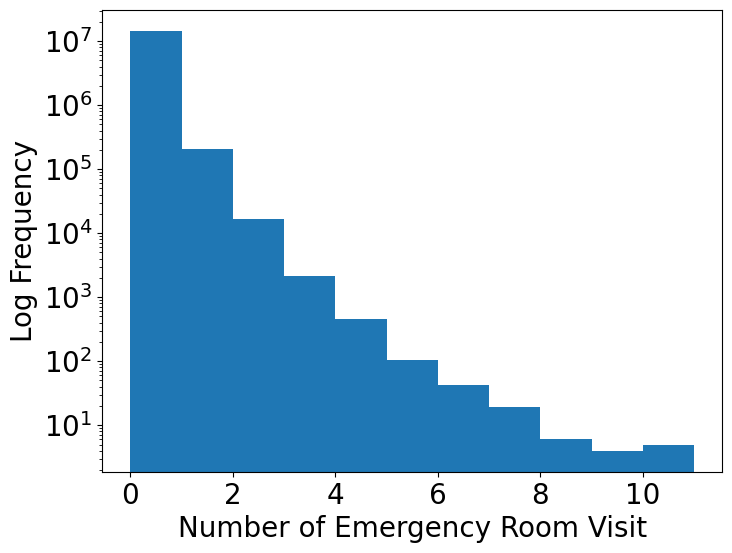

In [12]:
## check the distribution of outcomes: Office_PCP_Count, ER_Count
fig, ax = plt.subplots(figsize=(8, 6))
plt.yscale('log')
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
ax.set_xlabel('Number of Emergency Room Visit', fontsize=20)
ax.set_ylabel('Log Frequency', fontsize=20)
plt.hist(analysis2018["ER_Count"],bins=[0,1,2,3,4,5,6,7,8,9,10,11])
plt.show()

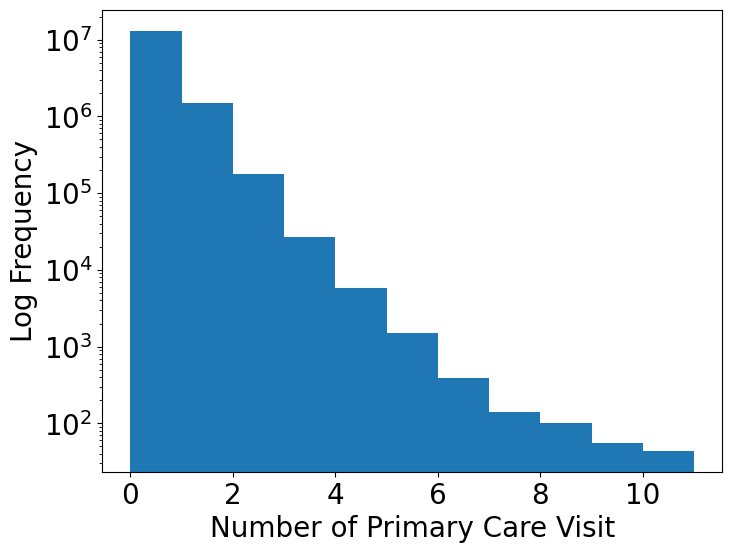

In [13]:
fig, ax = plt.subplots(figsize=(8, 6))
plt.yscale('log')
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
ax.set_xlabel('Number of Primary Care Visit', fontsize=20)
ax.set_ylabel('Log Frequency', fontsize=20)
plt.hist(analysis2018["Office_PCP_Count"],bins=[0,1,2,3,4,5,6,7,8,9,10,11])
plt.show()

In [ ]:
## Specify outcomes and convert into binary

## ER
analysis2018["admit_ER"] = (analysis2018["ER_Count"] >= 1) * 1
analysis2019["admit_ER"] = (analysis2019["ER_Count"] >= 1) * 1

## PCP
analysis2018["admit_PCP"] = (analysis2018["Office_PCP_Count"] >= 1) * 1
analysis2019["admit_PCP"] = (analysis2019["Office_PCP_Count"] >= 1) * 1

### zip level SDoH data

In [ ]:
# neighborhood SDoH data

sdoh_zip = pd.read_csv('../data/SDOH_zip.csv')
sdi = pd.read_csv('../data/rgcsdi-2015-2019-zcta.csv') 

In [ ]:
# merge the two
# print(sdoh_zip.columns.tolist())
# print(sdi.columns.tolist())

sdoh_zip = pd.merge(sdoh_zip, sdi, left_on='zip', right_on='ZCTA5_FIPS', how='left')

### race data

In [ ]:
# race_clean = pd.read_csv('../data_processed/race_clean.csv') 

In [ ]:
# race data

race = pd.read_csv('../data/edited_messy_rows_REL_Member_Information_Deidentified_NYU.csv') 

race['All_Combined_Race'].value_counts(normalize=True)

In [ ]:
# solve conflict race info

race_clean = (
    race.groupby('Member_Wid_DID')
    .apply(lambda g: g.assign(
        All_Combined_Race="Conflict" if len(g['All_Combined_Race'].unique()) > 1 else g['All_Combined_Race'].iloc[0]
    ))
    .drop_duplicates(subset='Member_Wid_DID', keep='first')
    .reset_index(drop=True)
)

race_clean['All_Combined_Race'].value_counts(normalize=True)

In [ ]:
# prepare for merging
race_clean = race_clean.rename(columns={'Member_Wid_DID': 'Member_Wid'})
# race_clean.to_csv("../data_processed/race_clean.csv", index=False)

### merge data

#### race

In [ ]:
# merge claim data with race
analysis2018_race = pd.merge(analysis2018, race_clean, on='Member_Wid', how='left')
analysis2019_race = pd.merge(analysis2019, race_clean, on='Member_Wid', how='left')

In [ ]:
# Replace NaN with 'Missing'
analysis2018_race['All_Combined_Race'] = analysis2018_race['All_Combined_Race'].fillna('Missing')
analysis2019_race['All_Combined_Race'] = analysis2019_race['All_Combined_Race'].fillna('Missing')

In [ ]:
# check proportions
# print(analysis2018_race['All_Combined_Race'].value_counts(dropna=False, normalize=True))
# print(analysis2019_race['All_Combined_Race'].value_counts(dropna=False, normalize=True))

In [ ]:
# recategorize
analysis2018_race['All_Combined_Race'] = analysis2018_race['All_Combined_Race'].replace({
    'Conflict': 'Others',
    'conflict': 'Others',
    'Asian': 'Others',
    'Native Hawaiian or Other Pacific Islander': 'Others',
    'American Indian or Alaska Native': 'Others'
})

In [ ]:
analysis2019_race['All_Combined_Race'] = analysis2019_race['All_Combined_Race'].replace({
    'Conflict': 'Others',
    'conflict': 'Others',
    'Asian': 'Others',
    'Native Hawaiian or Other Pacific Islander': 'Others',
    'American Indian or Alaska Native': 'Others'
})

In [ ]:
# dummy coding
analysis2018_race_dummies = pd.get_dummies(analysis2018_race['All_Combined_Race'], prefix='Race')
analysis2018_race = pd.concat([analysis2018_race, analysis2018_race_dummies], axis=1)

In [ ]:
analysis2019_race_dummies = pd.get_dummies(analysis2019_race['All_Combined_Race'], prefix='Race')
analysis2019_race = pd.concat([analysis2019_race, analysis2019_race_dummies], axis=1)

#### nSDoH

In [ ]:
## merge sdoh and zip code residence of the members
analysis2018_sdoh = pd.merge(analysis2018_race, sdoh_zip, 
                             left_on='Member_Home_Address_ZIP_Code_5_Current', right_on='zip', how='left')
analysis2019_sdoh = pd.merge(analysis2019_race, sdoh_zip, 
                             left_on='Member_Home_Address_ZIP_Code_5_Current', right_on='zip', how='left')

In [ ]:
## store raw data before preprocessing
analysis2018_sdoh.to_csv("../data_processed/analysis2018_raw.csv", index=False)
analysis2019_sdoh.to_csv("../data_processed/analysis2019_raw.csv", index=False)

### check missing data

In [ ]:
# 2018
percent_missing = analysis2018.isnull().sum() * 100 / len(analysis2018)
missing_value_df = pd.DataFrame({'column_name': analysis2018.columns,
                                 'percent_missing': percent_missing})
missing_value_df.sort_values(by=['percent_missing'], ascending=False)

In [ ]:
# 2019
percent_missing = analysis2019.isnull().sum() * 100 / len(analysis2019)
missing_value_df = pd.DataFrame({'column_name': analysis2019.columns,
                                 'percent_missing': percent_missing})
missing_value_df.sort_values(by=['percent_missing'], ascending=False)

# Data preprocessing

In [3]:
analysis2018 = pd.read_csv("../data_processed/analysis2018_raw.csv", low_memory=False)

In [16]:
filepath = "../../../xc2440/SDoH_insurance/data_processed/analysis2018_raw.csv"

df_sample = pd.read_csv(filepath, nrows=5)

df_sample

,Unnamed: 0_x,Member_Wid,Group_Wid,Hierarchy_Attr_Provider_Wid,Member_Medical_Count,Member_Drug_Count,Member_DOB_Age_Qty,Member_Has_Asthma_Episode_Ind,Member_Has_Burns_Episode_Ind,Member_Has_Cancer_Episode_Ind,Member_Has_CHF_Episode_Ind,Member_Has_CKD_Episode_Ind,Member_Has_Congenital_Anomalies_Episode_Ind,Member_Has_COPD_Episode_Ind,Member_Has_Crohns_Disease_Episode_Ind,Member_Has_Cystic_Fibrosis_Episode_Ind,Member_Has_Diabetes_Episode_Ind,Member_Has_Glaucoma_Episode_Ind,Member_Has_Heart_Pulmonary_Condition_Episode_Ind,Member_Has_Hepatitis_C_Episode_Ind,Member_Has_Hepatitis_Non_C_Episode_Ind,Member_Has_HIV_Episode_Ind,Member_Has_Hypertension_Episode_Ind,Member_Has_Immunity_Blood_Disorders_Episode_Ind,Member_Has_Low_Back_Pain_Episode_Ind,Member_Has_Mental_Health_Episode_Ind,Member_Has_Metabolic_Disorders_Episode_Ind,Member_Has_Multiple_Sclerosis_Episode_Ind,Member_Has_Neonatal_Condition_Episode_Ind,Member_Has_Parkinsons_Disease_Episode_Ind,Member_Has_Pregnancy_Episode_Ind,Member_Has_Renal_Failure_Episode_Ind,Member_Has_Rheumatoid_Arthritis_Episode_Ind,Member_Has_Spine_Pain_Episode_Ind,Member_Has_Transplant_Episode_Ind,Member_Has_ALS_Diag_Ind,Member_Has_AMI_Diag_Ind,Member_Has_Anxiety_Disorders_Diag_Ind,Member_Has_Asthma_Diag_Ind,Member_Has_Burns_Diag_Ind,Member_Has_Cancer_Diag_Ind,Member_Has_Cardiac_Congenital_Anomalies_Diag_Ind,Member_Has_CHF_Diag_Ind,Member_Has_CAD_Diag_Ind,Member_Has_Cerobrovascular_Disease_Diag_Ind,Member_Has_CIDP_Diag_Ind,Member_Has_CKD_Diag_Ind,Member_Has_Congenital_Hydrocephalus_Diag_Ind,Member_Has_Connective_Tissue_Disorder_Diag_Ind,Member_Has_COPD_Diag_Ind,Member_Has_Crohns_Diag_Ind,Member_Has_Cystic_Fibrosis_Diag_Ind,Member_Has_Depression_Diag_Ind,Member_Has_Dermatomyositis_Diag_Ind,Member_Has_Diabetes_Diag_Ind,Member_Has_Epilepsy_Diag_Ind,Member_Has_ESRD_Diag_Ind,Member_Has_Gaucher_Disease_Diag_Ind,Member_Has_Hemophilia_Diag_Ind,Member_Has_Hepatitis_Diag_Ind,Member_Has_HIV_Diag_Ind,Member_Has_HTN_Diag_Ind,Member_Has_Liver_Disease_Diag_Ind,Member_Has_Lupus_Diag_Ind,Member_Has_Multiple_Sclerosis_Diag_Ind,Member_Has_Myasthenia_Gravis_Diag_Ind,Member_Has_Myositis_Diag_Ind,Member_Has_Nephritis_Nephrosis_or_Sclerosis_Diag_Ind,Member_Has_Osteoarthritis_Diag_Ind,Member_Has_Other_Mental_Health_Diag_Ind,Member_Has_Other_Nerv_Sys_Congenital_Anomalies_Diag_Ind,Member_Has_Parkinsons_Diag_Ind,Member_Has_Peri_Endo_Myocarditis_or_Cardiomyopathy_Diag_Ind,Member_Has_Polymyositis_Diag_Ind,Member_Has_Pulmonary_Heart_Disease_Diag_Ind,Member_Has_RA_Diag_Ind,Member_Has_Resp_Failure_Insuff_Arrest_Diag_Ind,Member_Has_Scleroderma_Diag_Ind,Member_Has_Sickle_Cell_Anemia_Diag_Ind,Member_Has_Spina_Bifida_Diag_Ind,Member_Has_Spinal_Cord_Injury_Diag_Ind,Member_Has_Substance_Abuse_Disorder_Diag_Ind,Member_Has_Ulcerative_Colitis_Diag_Ind,Admit_Count,Admit_Allowed_Amt,Admit_Days,Acute_Admit_Count,Acute_Admit_Allowed_Amt,Acute_Admit_Days,Non_Acute_Admit_Count,Non_Acute_Admit_Allowed_Amt,Non_Acute_Admit_Days,Medical_Admit_Count,Medical_Admit_Allowed_Amt,Surgical_Admit_Count,Surgical_Admit_Allowed_Amt,Maternity_Admit_Count,Maternity_Admit_Allowed_Amt,Rehab_Admit_Count,Rehab_Admit_Allowed_Amt,MHSA_Admit_Count,MHSA_Admit_Allowed_Amt,LTAC_SNF_Admit_Count,LTAC_SNF_Admit_Allowed_Amt,Readmissions_15_Day_Count,Readmissions_30_Day_Count,Avoidable_Admit_Count,Avoidable_Diabetic_Short_Term_Admit_Count,Avoidable_Appendix_Admit_Count,Avoidable_Diabetic_Long_Term_Admit_Count,Avoidable_Older_Adult_COPD_Asthma_Admit_Count,Avoidable_Hypertension_Admit_Count,Avoidable_Heart_Failure_Admit_Count,Avoidable_Low_Birth_Weight_Admit_Count,Avoidable_Dehydration_Admit_Count,Avoidable_Comm_Acquired_Pneumonia_Admit_Count,Avoidable_Urinary_Tract_Infec_Admit_Count,Avoidable_Uncontrolled_Diabetes_Admit_Count,Avoidable_Young_Adult_Asthma_Admit_Count,Avoidable_Diabetic_Low_Ext_Amputation_Admit_Count,OP_Surgery_Count,OP_Surgery_Allowed_Amt,Office_PCP_Count,Office_PCP_Allowed_Amt,Office_Specialty_Count,Office_Specialty_Allowed_Amt,Urgent_Care_Count,Urgent_Care_Allowed_Am

In [4]:
analysis2019 = pd.read_csv("../data_processed/analysis2019_raw.csv", low_memory=False)

## analysis features

In [32]:
individual = ['Member_DOB_Age_Qty',
              'Member_Has_ALS_Diag_Ind','Member_Has_AMI_Diag_Ind',
              'Member_Has_Anxiety_Disorders_Diag_Ind','Member_Has_Asthma_Diag_Ind','Member_Has_Burns_Diag_Ind',
 'Member_Has_Cancer_Diag_Ind','Member_Has_Cardiac_Congenital_Anomalies_Diag_Ind','Member_Has_CHF_Diag_Ind',
 'Member_Has_CAD_Diag_Ind','Member_Has_Cerobrovascular_Disease_Diag_Ind','Member_Has_CIDP_Diag_Ind',
 'Member_Has_CKD_Diag_Ind','Member_Has_Congenital_Hydrocephalus_Diag_Ind',
              'Member_Has_Connective_Tissue_Disorder_Diag_Ind',
              'Member_Has_COPD_Diag_Ind','Member_Has_Crohns_Diag_Ind',
 'Member_Has_Cystic_Fibrosis_Diag_Ind',
 'Member_Has_Depression_Diag_Ind',
 'Member_Has_Dermatomyositis_Diag_Ind',
 'Member_Has_Diabetes_Diag_Ind',
 'Member_Has_Epilepsy_Diag_Ind',
 'Member_Has_ESRD_Diag_Ind',
 'Member_Has_Gaucher_Disease_Diag_Ind',
 'Member_Has_Hemophilia_Diag_Ind',
 'Member_Has_Hepatitis_Diag_Ind',
 'Member_Has_HIV_Diag_Ind',
 'Member_Has_HTN_Diag_Ind',
 'Member_Has_Liver_Disease_Diag_Ind',
 'Member_Has_Lupus_Diag_Ind',
 'Member_Has_Multiple_Sclerosis_Diag_Ind',
 'Member_Has_Myasthenia_Gravis_Diag_Ind',
 'Member_Has_Myositis_Diag_Ind',
 'Member_Has_Nephritis_Nephrosis_or_Sclerosis_Diag_Ind',
 'Member_Has_Osteoarthritis_Diag_Ind',
 'Member_Has_Other_Mental_Health_Diag_Ind',
 'Member_Has_Other_Nerv_Sys_Congenital_Anomalies_Diag_Ind',
 'Member_Has_Parkinsons_Diag_Ind',
 'Member_Has_Peri_Endo_Myocarditis_or_Cardiomyopathy_Diag_Ind',
 'Member_Has_Polymyositis_Diag_Ind',
 'Member_Has_Pulmonary_Heart_Disease_Diag_Ind',
 'Member_Has_RA_Diag_Ind',
 'Member_Has_Resp_Failure_Insuff_Arrest_Diag_Ind',
 'Member_Has_Scleroderma_Diag_Ind',
 'Member_Has_Sickle_Cell_Anemia_Diag_Ind',
 'Member_Has_Spina_Bifida_Diag_Ind',
 'Member_Has_Spinal_Cord_Injury_Diag_Ind',
 'Member_Has_Substance_Abuse_Disorder_Diag_Ind','Member_Has_Ulcerative_Colitis_Diag_Ind', 
                'Member_Is_Exchange_Member_Ind', 
                'Product_Is_ACA_Plan_Ind','Product_Is_Certified_QHP_Ind',
                'Product_Is_Supplemental_Ind',
                'Member_Marital_Status_Current_Divorced',
 'Member_Marital_Status_Current_Married',
 'Member_Marital_Status_Current_Single',
 'Member_Marital_Status_Current_Unknown',
 'Member_Marital_Status_Current_Widow(er)',
 'Product_Metal_Level_Bronze',
 'Product_Metal_Level_Gold',
 'Product_Metal_Level_Not Applicable',
 'Product_Metal_Level_Platinum',
 'Product_Metal_Level_Silver',
 'Product_Type_Not Applicable',
 'Product_Type_Other',
 'Product_Type_POS',
 'Product_Type_PPO',
 'Member_Gender_Current_Female',
 'Race_Black or African American',
 'Race_Hispanic or Latino',
 'Race_Missing',
 'Race_Others',
 'Race_White']

In [33]:
individual_sdoh = ['Member_DOB_Age_Qty',
                 'Member_Has_ALS_Diag_Ind',  'Member_Has_AMI_Diag_Ind',
 'Member_Has_Anxiety_Disorders_Diag_Ind','Member_Has_Asthma_Diag_Ind','Member_Has_Burns_Diag_Ind',
 'Member_Has_Cancer_Diag_Ind','Member_Has_Cardiac_Congenital_Anomalies_Diag_Ind','Member_Has_CHF_Diag_Ind',
 'Member_Has_CAD_Diag_Ind','Member_Has_Cerobrovascular_Disease_Diag_Ind','Member_Has_CIDP_Diag_Ind',
 'Member_Has_CKD_Diag_Ind','Member_Has_Congenital_Hydrocephalus_Diag_Ind',
                    'Member_Has_Connective_Tissue_Disorder_Diag_Ind',
 'Member_Has_COPD_Diag_Ind','Member_Has_Crohns_Diag_Ind',
 'Member_Has_Cystic_Fibrosis_Diag_Ind',
 'Member_Has_Depression_Diag_Ind',
 'Member_Has_Dermatomyositis_Diag_Ind',
 'Member_Has_Diabetes_Diag_Ind',
 'Member_Has_Epilepsy_Diag_Ind',
 'Member_Has_ESRD_Diag_Ind',
 'Member_Has_Gaucher_Disease_Diag_Ind',
 'Member_Has_Hemophilia_Diag_Ind',
 'Member_Has_Hepatitis_Diag_Ind',
 'Member_Has_HIV_Diag_Ind',
 'Member_Has_HTN_Diag_Ind',
 'Member_Has_Liver_Disease_Diag_Ind',
 'Member_Has_Lupus_Diag_Ind',
 'Member_Has_Multiple_Sclerosis_Diag_Ind',
 'Member_Has_Myasthenia_Gravis_Diag_Ind',
 'Member_Has_Myositis_Diag_Ind',
 'Member_Has_Nephritis_Nephrosis_or_Sclerosis_Diag_Ind',
 'Member_Has_Osteoarthritis_Diag_Ind',
 'Member_Has_Other_Mental_Health_Diag_Ind',
 'Member_Has_Other_Nerv_Sys_Congenital_Anomalies_Diag_Ind',
 'Member_Has_Parkinsons_Diag_Ind',
 'Member_Has_Peri_Endo_Myocarditis_or_Cardiomyopathy_Diag_Ind',
 'Member_Has_Polymyositis_Diag_Ind',
 'Member_Has_Pulmonary_Heart_Disease_Diag_Ind',
 'Member_Has_RA_Diag_Ind',
 'Member_Has_Resp_Failure_Insuff_Arrest_Diag_Ind',
 'Member_Has_Scleroderma_Diag_Ind',
 'Member_Has_Sickle_Cell_Anemia_Diag_Ind',
 'Member_Has_Spina_Bifida_Diag_Ind',
 'Member_Has_Spinal_Cord_Injury_Diag_Ind',
 'Member_Has_Substance_Abuse_Disorder_Diag_Ind','Member_Has_Ulcerative_Colitis_Diag_Ind', 
                'Member_Is_Exchange_Member_Ind', 
                'Product_Is_ACA_Plan_Ind','Product_Is_Certified_QHP_Ind',
                'Product_Is_Supplemental_Ind',
 'ACS_PCT_ENGL_NOT_ALL',
 'ACS_PCT_FEMALE',
 'ACS_PCT_FOREIGN_BORN',
 'ACS_PCT_LIMIT_ENGLISH',
 'ACS_PCT_NON_CITIZEN',
 'ACS_PCT_1UP_PERS_1ROOM',
 'ACS_PCT_AGE_65UP',
 'ACS_PCT_ASIAN',
 'ACS_PCT_BLACK',
 'ACS_PCT_HISPAN',
 'ACS_PCT_WHITE',
 'ACS_PCT_DISABLE',
 'ACS_HH_SIZE',
 'ACS_PCT_DIVORCE_SEPARAT',
 'ACS_PCT_HH_NO_FUEL',
 'ACS_PCT_ADMIN',
 'ACS_PCT_CONSTRUCT',
 'ACS_PCT_EDUC',
 'ACS_PCT_FINANCE',
 'ACS_PCT_MANUFACT',
 'ACS_PCT_NATURE',
 'ACS_PCT_PROFESS',
 'ACS_PCT_RETAIL',
 'ACS_PCT_TRANSPORT',
 'ACS_PCT_UNEMPLOY',
 'ACS_PCT_NONVA_POOR',
 'ACS_GINI_INDEX',
 'ACS_MEDIAN_HH_INCOME',
 'ACS_PCT_FOOD_STAMP',
 'ACS_PCT_HH_PUB_ASSIST',
 'ACS_PCT_BACHELOR_DGR',
 'ACS_PCT_LT_HS',
 'ACS_PCT_GRP_QRT',
 'CCBP_RATE_CS_PER_1000',
 'ACS_PCT_NO_VEH',
 'ACS_PCT_MEDICAID_ANY64',
 'ACS_PCT_PRIVATE_ANY64',
 'ACS_PCT_PRIVATE_EMPL64',
 'ACS_PCT_UNINSURED64',
 'ACS_PCT_UNINSURED','any_open_park','count_open_parks',
 'count_tri_facilities',
                   'Member_Marital_Status_Current_Unknown',
                   'Member_Marital_Status_Current_Divorced',
 'Member_Marital_Status_Current_Married',
 'Member_Marital_Status_Current_Single',
 'Member_Marital_Status_Current_Widow(er)',
 'Product_Metal_Level_Bronze',
 'Product_Metal_Level_Gold',
 'Product_Metal_Level_Platinum',
 'Product_Metal_Level_Silver',
                   'Product_Metal_Level_Not Applicable',
  'Product_Type_Not Applicable',
 'Product_Type_Other',
 'Product_Type_POS',
 'Product_Type_PPO',
 'Member_Gender_Current_Female',
 'Race_Black or African American',
 'Race_Hispanic or Latino',
 'Race_Missing',
 'Race_Others',
 'Race_White']

In [34]:
individual_sdi = ['Member_DOB_Age_Qty','Member_Has_ALS_Diag_Ind','Member_Has_AMI_Diag_Ind',
              'Member_Has_Anxiety_Disorders_Diag_Ind','Member_Has_Asthma_Diag_Ind','Member_Has_Burns_Diag_Ind',
 'Member_Has_Cancer_Diag_Ind','Member_Has_Cardiac_Congenital_Anomalies_Diag_Ind','Member_Has_CHF_Diag_Ind',
 'Member_Has_CAD_Diag_Ind','Member_Has_Cerobrovascular_Disease_Diag_Ind','Member_Has_CIDP_Diag_Ind',
 'Member_Has_CKD_Diag_Ind','Member_Has_Congenital_Hydrocephalus_Diag_Ind',
              'Member_Has_Connective_Tissue_Disorder_Diag_Ind',
              'Member_Has_COPD_Diag_Ind','Member_Has_Crohns_Diag_Ind',
 'Member_Has_Cystic_Fibrosis_Diag_Ind',
 'Member_Has_Depression_Diag_Ind',
 'Member_Has_Dermatomyositis_Diag_Ind',
 'Member_Has_Diabetes_Diag_Ind',
 'Member_Has_Epilepsy_Diag_Ind',
 'Member_Has_ESRD_Diag_Ind',
 'Member_Has_Gaucher_Disease_Diag_Ind',
 'Member_Has_Hemophilia_Diag_Ind',
 'Member_Has_Hepatitis_Diag_Ind',
 'Member_Has_HIV_Diag_Ind',
 'Member_Has_HTN_Diag_Ind',
 'Member_Has_Liver_Disease_Diag_Ind',
 'Member_Has_Lupus_Diag_Ind',
 'Member_Has_Multiple_Sclerosis_Diag_Ind',
 'Member_Has_Myasthenia_Gravis_Diag_Ind',
 'Member_Has_Myositis_Diag_Ind',
 'Member_Has_Nephritis_Nephrosis_or_Sclerosis_Diag_Ind',
 'Member_Has_Osteoarthritis_Diag_Ind',
 'Member_Has_Other_Mental_Health_Diag_Ind',
 'Member_Has_Other_Nerv_Sys_Congenital_Anomalies_Diag_Ind',
 'Member_Has_Parkinsons_Diag_Ind',
 'Member_Has_Peri_Endo_Myocarditis_or_Cardiomyopathy_Diag_Ind',
 'Member_Has_Polymyositis_Diag_Ind',
 'Member_Has_Pulmonary_Heart_Disease_Diag_Ind',
 'Member_Has_RA_Diag_Ind',
 'Member_Has_Resp_Failure_Insuff_Arrest_Diag_Ind',
 'Member_Has_Scleroderma_Diag_Ind',
 'Member_Has_Sickle_Cell_Anemia_Diag_Ind',
 'Member_Has_Spina_Bifida_Diag_Ind',
 'Member_Has_Spinal_Cord_Injury_Diag_Ind',
 'Member_Has_Substance_Abuse_Disorder_Diag_Ind','Member_Has_Ulcerative_Colitis_Diag_Ind', 
                'Member_Is_Exchange_Member_Ind', 
                'Product_Is_ACA_Plan_Ind','Product_Is_Certified_QHP_Ind',
                'Product_Is_Supplemental_Ind',
                'Member_Marital_Status_Current_Divorced',
 'Member_Marital_Status_Current_Married',
 'Member_Marital_Status_Current_Single',
 'Member_Marital_Status_Current_Unknown',
 'Member_Marital_Status_Current_Widow(er)',
 'Product_Metal_Level_Bronze',
 'Product_Metal_Level_Gold',
 'Product_Metal_Level_Not Applicable',
 'Product_Metal_Level_Platinum',
 'Product_Metal_Level_Silver',
  'Product_Type_Not Applicable',
 'Product_Type_Other',
 'Product_Type_POS',
 'Product_Type_PPO',
 'Member_Gender_Current_Female',
 'Race_Black or African American',
 'Race_Hispanic or Latino',
 'Race_Missing',
 'Race_Others',
 'Race_White',
                  'sdi']

In [35]:
# all features
all_features = list(set(individual_sdi + individual_sdoh + individual))
all_features.extend(["Member_Wid", "com1",'admit_ER','admit_PCP'])
print(len(all_features))

121


In [10]:
for col in all_features:
    if col in analysis2018.columns:
        dtype = analysis2018[col].dtype
        has_na = analysis2018[col].isnull().any()
        na_msg = "❗ NaNs present" if has_na else "✅ No NaNs"
        dtype_msg = "❗ not float" if dtype != 'float64' and dtype != 'float64' else "✅ float"
        print(f"{col}: ✅ exists | dtype: {dtype} ({dtype_msg}) | {na_msg}")
    else:
        print(f"{col}: ❌ does NOT exist")
        
## individual indicator features are int64, no NaN
## race are int64
## nSDoH are float64 with NaNs
## ind categorical variables needs recategorization 

Member_Has_Connective_Tissue_Disorder_Diag_Ind: ✅ exists | dtype: int64 (❗ not float) | ✅ No NaNs
Member_Has_CHF_Diag_Ind: ✅ exists | dtype: int64 (❗ not float) | ✅ No NaNs
Member_Has_ESRD_Diag_Ind: ✅ exists | dtype: int64 (❗ not float) | ✅ No NaNs
ACS_PCT_UNEMPLOY: ✅ exists | dtype: float64 (✅ float) | ❗ NaNs present
ACS_PCT_PROFESS: ✅ exists | dtype: float64 (✅ float) | ❗ NaNs present
Member_Has_CAD_Diag_Ind: ✅ exists | dtype: int64 (❗ not float) | ✅ No NaNs
ACS_PCT_FOOD_STAMP: ✅ exists | dtype: float64 (✅ float) | ❗ NaNs present
Member_Has_Hemophilia_Diag_Ind: ✅ exists | dtype: int64 (❗ not float) | ✅ No NaNs
ACS_PCT_UNINSURED64: ✅ exists | dtype: float64 (✅ float) | ❗ NaNs present
Race_Hispanic or Latino: ✅ exists | dtype: int64 (❗ not float) | ✅ No NaNs
Member_Has_CKD_Diag_Ind: ✅ exists | dtype: int64 (❗ not float) | ✅ No NaNs
ACS_PCT_HH_NO_FUEL: ✅ exists | dtype: float64 (✅ float) | ❗ NaNs present
ACS_PCT_RETAIL: ✅ exists | dtype: float64 (✅ float) | ❗ NaNs present
ACS_PCT_AGE_65

In [ ]:
cols_to_check = [
    'Member_Is_Exchange_Member_Ind',
    'Product_Is_ACA_Plan_Ind',
    'Product_Is_Certified_QHP_Ind',
    'Product_Is_Supplemental_Ind',
    'Member_Marital_Status_Current',
    'Product_Metal_Level',
    'Product_Type',
    'Member_Gender_Current'
]

for col in cols_to_check:
    print(f"\nValue counts for {col}:\n")
    print(analysis2018[col].value_counts(dropna=False))
    
    if analysis2018[col].isnull().any():
        print(f"➡️  NaN values exist in '{col}'")
    else:
        print(f"✅ No NaN values in '{col}'")

## train/test split

In [11]:
## train on 2018 data and tested on 2019 data
train = analysis2018
test = analysis2019

## preprocessing

In [ ]:
# dummy coding for categorical variables

In [12]:
binary_vars = [
    'Member_Is_Exchange_Member_Ind',
    'Product_Is_ACA_Plan_Ind',
    'Product_Is_Certified_QHP_Ind',
    'Product_Is_Supplemental_Ind'
]

train[binary_vars] = train[binary_vars].replace({'Y': 1, 'N': 0}).astype(int)
test[binary_vars] = test[binary_vars].replace({'Y': 1, 'N': 0}).astype(int)

train['Member_Gender_Current_Female'] = (train['Member_Gender_Current'] == 'Female').astype(int)
test['Member_Gender_Current_Female'] = (test['Member_Gender_Current'] == 'Female').astype(int)

In [17]:
marital_map = {
    'Undefined': 'Unknown',
    'Unreported': 'Unknown',
    'Legally Separated': 'Divorced',
    'Separated': 'Divorced',
    'Life Partner (Dom, Partner or Sig Other)': 'Single',
    'Unmarried': 'Single'
}

metal_map = {
    'Undefined': 'Not Applicable',
    'Invalid Value': 'Not Applicable'
}

product_type_map = {
    'Traditional': 'Other',
    'HMO': 'Other',
    'Medicare Advantage': 'Other',
    'CSD': 'Other',
    'Contract Only': 'Other',
    'Dental': 'Other',
    'Short Term Medical': 'Other',
    'VIP': 'Other',
    'Undefined': 'Not Applicable',
    'Invalid Value': 'Not Applicable'
}

cols = [
    'Member_Marital_Status_Current',
    'Product_Metal_Level',
    'Product_Type'
]


dummy_frames = [
    pd.get_dummies(train[col], prefix=col) for col in cols
]
train = pd.concat([train] + dummy_frames, axis=1)

dummy_frames_test = [
    pd.get_dummies(test[col], prefix=col) for col in cols
]
test = pd.concat([test] + dummy_frames_test, axis=1)

In [14]:
## age to float type
train['Member_DOB_Age_Qty'] = train['Member_DOB_Age_Qty'].astype('float64')
test['Member_DOB_Age_Qty'] = test['Member_DOB_Age_Qty'].astype('float64')

In [15]:
def pre_processing(train_set, test_set, para_list):
    train = train_set[para_list]
    test = test_set[para_list]
    
    x_train = train.drop(['admit_PCP', 'admit_ER'], axis=1)
    y_train = train[["Member_Wid",'admit_PCP', 'admit_ER']]
        
    x_test = test.drop(['admit_PCP', 'admit_ER'], axis=1)
    y_test = test[["Member_Wid",'admit_PCP', 'admit_ER']]
    
    # continous feature missing imputation
    x_train_continuous = x_train.select_dtypes(include='float64')
    x_test_continuous = x_test.select_dtypes(include='float64')
    imputer = SimpleImputer(strategy='median')
    x_train_continuous = pd.DataFrame(imputer.fit_transform(x_train_continuous), 
                                      index=x_train_continuous.index, 
                                      columns=x_train_continuous.columns)
    x_test_continuous = pd.DataFrame(imputer.transform(x_test_continuous), 
                                     index=x_test_continuous.index, 
                                     columns=x_test_continuous.columns)
    
    # categorical feature missing imputation
    x_train_cate = x_train.select_dtypes(exclude=['float64'])
    x_test_cate = x_test.select_dtypes(exclude=['float64'])
    ## no missing values
    
    # continuous feature standardization
    scaler = StandardScaler()
    x_train_continuous = pd.DataFrame(scaler.fit_transform(x_train_continuous), 
                                      index=x_train_continuous.index, 
                                      columns=x_train_continuous.columns)
    x_test_continuous = pd.DataFrame(scaler.transform(x_test_continuous), 
                                     index=x_test_continuous.index, 
                                     columns=x_test_continuous.columns)
    
    # combine con & cate features
    x_train = pd.concat([x_train_continuous, x_train_cate], axis=1)
    x_test = pd.concat([x_test_continuous, x_test_cate], axis=1)
        
    return x_train,y_train,x_test,y_test

In [19]:
x_train, y_train, x_test, y_test = pre_processing(train, test, all_features)
#x_train, y_train, x_test, y_test = pre_processing(train, test, individual_sdoh)
#x_train, y_train, x_test, y_test = pre_processing(train, test, svi_sdoh_index)

In [28]:
# save processed data
x_train.to_csv('../data_processed/x_train.csv', index=False)
y_train.to_csv('../data_processed/y_train.csv', index=False)
x_test.to_csv('../data_processed/x_test.csv', index=False)
y_test.to_csv('../data_processed/y_test.csv', index=False)

## create sample dataset for testing codes

In [3]:
# read in data
x_train = pd.read_csv('../data_processed/x_train.csv')
y_train = pd.read_csv('../data_processed/y_train.csv')
x_test = pd.read_csv('../data_processed/x_test.csv')
y_test = pd.read_csv('../data_processed/y_test.csv')

In [4]:
sample_frac = 0.1
seed = 42

x_train_sample = x_train.sample(frac=sample_frac, random_state=seed)
y_train_sample = y_train.loc[x_train_sample.index]

x_test_sample = x_test.sample(frac=sample_frac, random_state=seed)
y_test_sample = y_test.loc[x_test_sample.index]

In [6]:
# store
x_train_sample.to_csv('../data_processed/x_train_sample.csv', index=False)
y_train_sample.to_csv('../data_processed/y_train_sample.csv', index=False)
x_test_sample.to_csv('../data_processed/x_test_sample.csv', index=False)
y_test_sample.to_csv('../data_processed/y_test_sample.csv', index=False)